In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/uber.csv')

df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
print(df.head())
print(df.info())
print(df.isnull().sum())

   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             

In [ ]:
from math import radians, sin, cos, asin, sqrt

df = df.dropna().copy()

df = df[
    (df['fare_amount'] > 0) &
    (df['passenger_count'].between(1, 6)) &
    (df['pickup_longitude'].between(-75, -72)) &
    (df['dropoff_longitude'].between(-75, -72)) &
    (df['pickup_latitude'].between(40, 42)) &
    (df['dropoff_latitude'].between(40, 42))
].copy()

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], utc=True
)

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['weekday'] = df['pickup_datetime'].dt.dayofweek

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 6371 * 2 * asin(sqrt(a))

df['distance_km'] = df.apply(
    lambda r: haversine(
        r['pickup_latitude'], r['pickup_longitude'],
        r['dropoff_latitude'], r['dropoff_longitude']
    ), axis=1
)

df = df[
    (df['distance_km'] > 0) &
    (df['distance_km'] < 100)
].copy()

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (193059, 13)


Number of fare outliers: 16516


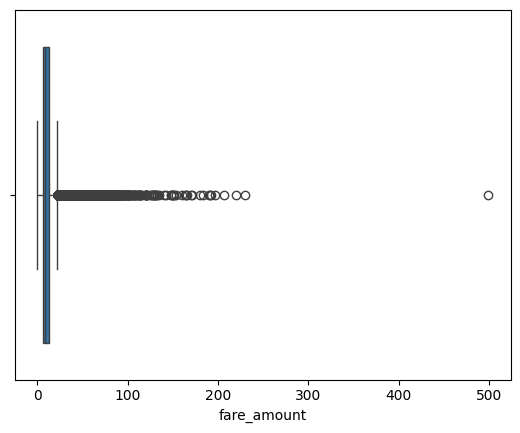

In [ ]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df['fare_amount'] < Q1 - 1.5 * IQR) |
    (df['fare_amount'] > Q3 + 1.5 * IQR)
]

print("Number of fare outliers:", len(outliers))

sns.boxplot(x=df['fare_amount'])
plt.show()

# Remove extreme fare outliers
df = df[
    (df['fare_amount'] >= max(0, Q1 - 1.5 * IQR)) &
    (df['fare_amount'] <= Q3 + 1.5 * IQR)
].copy()

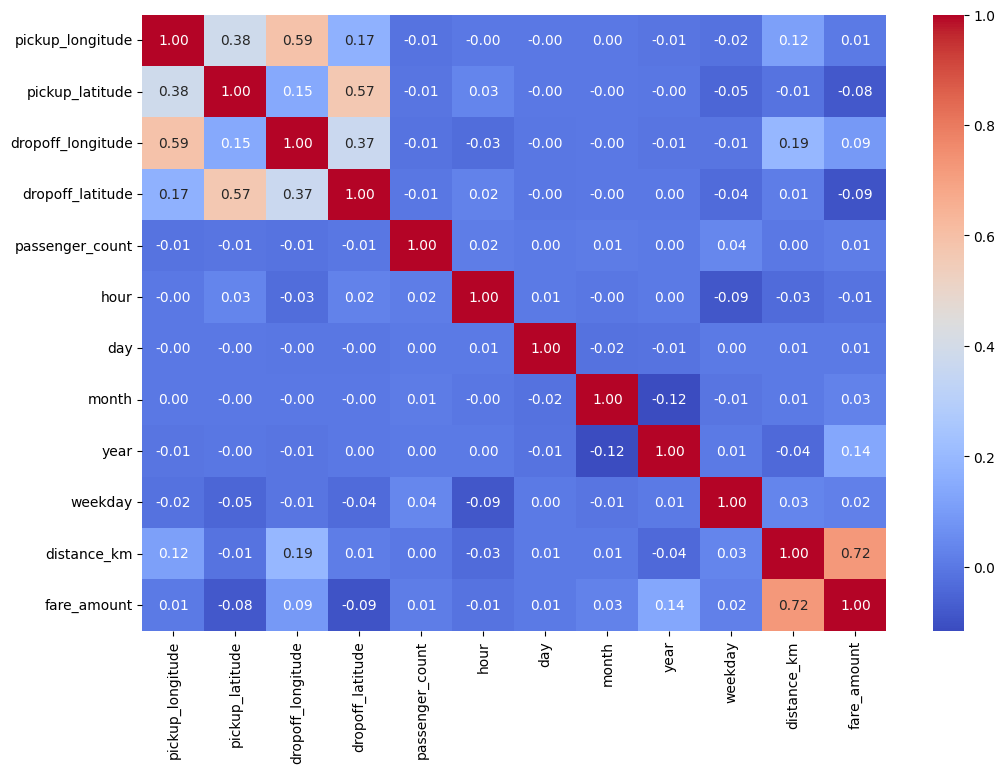

fare_amount          1.000000
distance_km          0.723707
year                 0.135764
dropoff_longitude    0.092930
month                0.026724
weekday              0.020450
passenger_count      0.012923
day                  0.006564
pickup_longitude     0.006453
hour                -0.013072
pickup_latitude     -0.083592
dropoff_latitude    -0.094295
Name: fare_amount, dtype: float64


In [ ]:
features = [
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'passenger_count', 'hour', 'day', 'month',
    'year', 'weekday', 'distance_km', 'fare_amount'
]

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[features].corr(),
    annot=True, cmap='coolwarm', fmt='.2f'
)
plt.show()

print(df[features].corr()['fare_amount'].sort_values(
    ascending=False
))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error
)

In [ ]:
X = df[[
    'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'passenger_count', 'hour', 'day', 'month',
    'year', 'weekday', 'distance_km'
]]

In [ ]:
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [ ]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("build")

build


In [ ]:
results = []
for name, pred in [
    ('Linear Regression', lr_pred),
    ('Random Forest', rf_pred)
]:
    results.append({
        'Model': name,
        'R2 Score': r2_score(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE': mean_absolute_error(y_test, pred)
    })
results_df = pd.DataFrame(results)
print(results_df.round(4))

               Model  R2 Score    RMSE     MAE
0  Linear Regression    0.5700  2.7178  1.7822
1      Random Forest    0.7827  1.9319  1.3307


In [ ]:
sample = X_test.iloc[[0]]
predicted_fare = rf.predict(sample)[0]
print(f"Predicted Uber fare: ${predicted_fare:.2f}")

Predicted Uber fare: $9.61
